# Notebook 1. Embeddings



Objetivo: entender qué es un embedding, cómo se mide la similitud entre textos y qué cambia entre modelos.
Usamos tres modelos multilingües: BGE-M3 (por defecto), Qwen3-Embedding-0.6B y multilingual-e5-large.

Referencias:
- Ficha de BGE-M3: https://huggingface.co/BAAI/bge-m3 (artículo: https://arxiv.org/abs/2402.03216)
- Ficha de Qwen3-Embedding-0.6B: https://huggingface.co/Qwen/Qwen3-Embedding-0.6B
- Ficha de multilingual-e5-large: https://huggingface.co/intfloat/multilingual-e5-large

In [ ]:
from rag_lab import CFG, set_seeds, summary

CFG.FAST_MODE = False  # corpus de control completo (por defecto se lee FAST_MODE de .env)
CFG.DOC_PATH = CFG.DATA_DIR / "mi_documento.pdf"  # cualquier PDF sirve
set_seeds()
summary()

Rag Lab inicializado con éxito en modo compatible (Fallback).
GPU disponible: False


## 1. Qué es un embedding

Un modelo de embeddings convierte un texto en un vector de longitud fija. Textos con significado parecido
quedan cerca en ese espacio. BGE-M3 produce vectores de 1024 dimensiones. `rag_lab.models.embed`
carga el modelo en fp16 si hay GPU, aplica el prefijo que pide su ficha y guarda los vectores en disco.

In [ ]:
import numpy as np
from rag_lab import models

sentences = [
    "El tren a Bilbao sale a las ocho de la mañana.",
    "Mañana a las 8 sale el tren hacia Bilbao.",
    "Los domingos cocino paella para toda la familia.",
]
vectors = models.embed(sentences, role="doc", model="BAAI/bge-m3")
print("Forma:", vectors.shape)
print("Primeras 8 componentes de la frase 1:", vectors[0][:8].round(4))
print(models.gpu_memory())

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.27GB            

... (8 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

Forma: (3, 1024)
Primeras 8 componentes de la frase 1: [-0.001   0.011  -0.0537  0.0002 -0.0299 -0.0079  0.0265  0.0288]
GPU no disponible


## 2. Similitud coseno

La similitud coseno es el producto escalar dividido por el producto de las normas: 1 si los vectores apuntan
igual, 0 si son ortogonales. Como `embed` devuelve vectores normalizados, basta con el producto escalar.

In [ ]:
def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

for i in range(len(sentences)):
    for j in range(i + 1, len(sentences)):
        print(f"{cosine(vectors[i], vectors[j]):.3f}  |  {sentences[i]}  <->  {sentences[j]}")
print("Producto escalar de 1 y 2:", round(float(vectors[0] @ vectors[1]), 3))

0.955  |  El tren a Bilbao sale a las ocho de la mañana.  <->  Mañana a las 8 sale el tren hacia Bilbao.
0.419  |  El tren a Bilbao sale a las ocho de la mañana.  <->  Los domingos cocino paella para toda la familia.
0.460  |  Mañana a las 8 sale el tren hacia Bilbao.  <->  Los domingos cocino paella para toda la familia.
Producto escalar de 1 y 2: 0.955


## 3. Visualización en 2D

Proyectamos con PCA frases de cuatro temas. Si el modelo captura el significado, cada tema forma un grupo.
La proyección a 2D pierde información: sirve para intuir, no para medir.

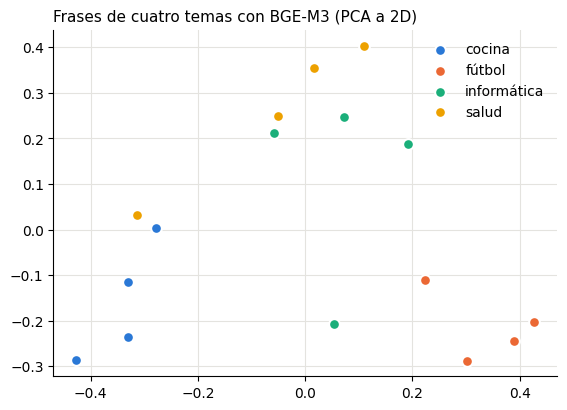

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

topics = {
    "cocina": ["La paella lleva arroz, azafrán y caldo.", "Hornea el bizcocho cuarenta minutos.",
               "Corta la cebolla en juliana fina.", "El marmitako es un guiso de bonito."],
    "fútbol": ["El delantero marcó de penalti en el último minuto.", "El árbitro expulsó al defensa.",
               "El equipo ganó la liga tras empatar el domingo.", "El portero detuvo el lanzamiento."],
    "informática": ["El servidor se reinició tras la actualización.", "Despliega el contenedor con Docker.",
                    "La consulta SQL tarda demasiado.", "El pipeline de CI ejecuta los tests."],
    "salud": ["El paciente tiene fiebre y tos seca.", "Toma el antibiótico cada ocho horas.",
              "La enfermera midió la tensión arterial.", "El médico pidió una analítica completa."],
}
texts = [t for group in topics.values() for t in group]
labels = [topic for topic, group in topics.items() for _ in group]
coords = PCA(n_components=2, random_state=CFG.SEED).fit_transform(models.embed(texts, "doc", "BAAI/bge-m3"))

palette = dict(zip(topics, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for topic in topics:
    idx = [i for i, e in enumerate(labels) if e == topic]
    ax.scatter(coords[idx, 0], coords[idx, 1], s=60, color=palette[topic], label=topic, edgecolor="white", linewidth=1.5)
ax.set_title("Frases de cuatro temas con BGE-M3 (PCA a 2D)", loc="left", fontsize=11)
ax.legend(frameon=False)
ax.grid(color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

## 4. Búsqueda semántica mínima

Buscar es codificar la consulta, calcular su similitud con cada documento y ordenar. Ojo al rol:
la consulta se codifica como `query` y los documentos como `doc`, porque algunos modelos usan prefijos distintos.

In [ ]:
corpus = [
    "La matrícula del ciclo formativo se abre en septiembre.",
    "El proyecto se financia con fondos europeos NextGenerationEU.",
    "Los alumnos harán prácticas en empresas del sector.",
    "El sistema despliega modelos de IA en la nube con integración continua.",
    "La cafetería del centro abre a las ocho.",
    "Se medirá la satisfacción del alumnado con encuestas.",
    "El presupuesto total del proyecto supera los cien mil euros.",
    "Las clases de programación se imparten por la tarde.",
]

def search(query, corpus, model="BAAI/bge-m3", k=3):
    q = models.embed([query], "query", model)[0]
    d = models.embed(corpus, "doc", model)
    scores = d @ q
    return [(round(float(scores[i]), 3), corpus[i]) for i in np.argsort(-scores)[:k]]

for query in ["¿Quién paga el proyecto?", "¿Cómo se evaluará la opinión de los estudiantes?"]:
    print(query)
    for score, text in search(query, corpus):
        print("  ", score, text)

¿Quién paga el proyecto?
   0.617 El presupuesto total del proyecto supera los cien mil euros.
   0.612 El proyecto se financia con fondos europeos NextGenerationEU.
   0.441 Los alumnos harán prácticas en empresas del sector.
¿Cómo se evaluará la opinión de los estudiantes?
   0.725 Se medirá la satisfacción del alumnado con encuestas.
   0.558 Los alumnos harán prácticas en empresas del sector.
   0.461 La matrícula del ciclo formativo se abre en septiembre.


## 5. Tres modelos y sus prefijos

Cada modelo se entrenó con un formato de entrada concreto y hay que respetarlo:
- BGE-M3: sin instrucción ni prefijo.
- Qwen3-Embedding: instrucción solo en la consulta (`prompt_name="query"`), nada en los documentos.
- multilingual-e5: `query: ` en la consulta y `passage: ` en los documentos.

In [ ]:
import pandas as pd

print(pd.DataFrame(models.PROFILES).T.fillna(""))
qwen = models.sentence_transformer("Qwen/Qwen3-Embedding-0.6B")
print("\nInstrucción de Qwen3 para consultas:", repr(qwen.prompts["query"]))
del qwen
models.release()

                               prompt_name
BAAI/bge-m3                               
Qwen/Qwen3-Embedding-0.6B            query
intfloat/multilingual-e5-large            


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/17.2k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.19GB            

... (5 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/313 [00:00<?, ?B/s]


Instrucción de Qwen3 para consultas: 'Instruct: Given a web search query, retrieve relevant passages that answer the query\nQuery:'


In [ ]:
from rag_lab import models
import numpy as np
import pandas as pd

def search(query, corpus, model="BAAI/bge-m3", k=3):
    q = models.embed([query], "query", model)[0]
    d = models.embed(corpus, "doc", model)
    scores = d @ q
    return [(round(float(scores[i]), 3), corpus[i]) for i in np.argsort(-scores)[:k]]

MODELS = ["BAAI/bge-m3", "Qwen/Qwen3-Embedding-0.6B", "intfloat/multilingual-e5-large"]
queries = ["¿Quién paga el proyecto?", "¿Cuándo empieza la matrícula?", "¿Dónde se despliegan los modelos?"]

rows = []
for model in MODELS:
    for query in queries:
        score, text = search(query, corpus, model, k=1)[0]
        rows.append({"modelo": model.split("/")[1], "consulta": query, "top-1": text, "similitud": score})
    models.release()  # un modelo cada vez en la GPU
pd.DataFrame(rows).pivot(index="consulta", columns="modelo", values="similitud")

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/160k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/690 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/201 [00:00<?, ?B/s]

modelo,Qwen3-Embedding-0.6B,bge-m3,multilingual-e5-large
consulta,,,
¿Cuándo empieza la matrícula?,0.749,0.775,0.853
¿Dónde se despliegan los modelos?,0.454,0.533,0.821
¿Quién paga el proyecto?,0.570,0.617,0.831


Las similitudes no son comparables entre modelos: cada uno tiene su propia escala. Lo que importa es el orden.
Veamos qué pasa si nos saltamos el prefijo de e5.

In [ ]:
e5 = models.sentence_transformer("intfloat/multilingual-e5-large")
query = "¿Quién paga el proyecto?"
with_prefix = models.embed(corpus, "doc", "intfloat/multilingual-e5-large") @ models.embed([query], "query", "intfloat/multilingual-e5-large")[0]
no_prefix = (e5.encode(corpus, normalize_embeddings=True) @ e5.encode([query], normalize_embeddings=True)[0]).astype("float32")
del e5
models.release()
pd.DataFrame({"documento": corpus, "con prefijos": with_prefix.round(3), "sin prefijos": no_prefix.round(3)}).sort_values("con prefijos", ascending=False)

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

,documento,con prefijos,sin prefijos
1,El proyecto se financia con fondos europeos Ne...,0.831,0.837
6,El presupuesto total del proyecto supera los c...,0.824,0.844
0,La matrícula del ciclo formativo se abre en se...,0.761,0.771
2,Los alumnos harán prácticas en empresas del se...,0.760,0.765
3,El sistema despliega modelos de IA en la nube ...,0.759,0.764
5,Se medirá la satisfacción del alumnado con enc...,0.754,0.759
7,Las clases de programación se imparten por la ...,0.737,0.764
4,La cafetería del centro abre a las ocho.,0.723,0.726


## 6. Entre idiomas

Comprobamos si cada modelo coloca cerca la misma idea escrita en idiomas distintos. Comparamos una consulta en
español con la misma frase en otros idiomas y con una frase en español que no tiene nada que ver.
Fíjate en el euskera y en la frase de otro tema: no todos los modelos se comportan igual.

In [ ]:
query = "¿A qué hora sale el tren?"
docs = {
    "es": "El tren sale a las ocho.",
    "en": "The train leaves at eight o'clock.",
    "fr": "Le train part à huit heures.",
    "eu": "Trena zortzietan ateratzen da.",
    "es (otro tema)": "La biblioteca cierra en agosto.",
}
table = {}
for model in MODELS:
    q = models.embed([query], "query", model)[0]
    d = models.embed(list(docs.values()), "doc", model)
    table[model.split("/")[1]] = (d @ q).round(3)
    models.release()
pd.DataFrame(table, index=list(docs))

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

,bge-m3,Qwen3-Embedding-0.6B,multilingual-e5-large
es,0.848,0.744,0.863
en,0.814,0.627,0.805
fr,0.836,0.631,0.822
eu,0.831,0.234,0.855
es (otro tema),0.385,0.259,0.715


## 7. Frases parecidas con significado distinto

Un embedding resume el texto en un vector y pierde matices: orden de los papeles, negaciones, cifras.
Por eso dos frases con las mismas palabras y significado opuesto pueden tener una similitud muy alta.

In [ ]:
pairs = [
    ("El perro mordió al cartero.", "El cartero mordió al perro."),
    ("El tratamiento es eficaz.", "El tratamiento no es eficaz."),
    ("El presupuesto es de 4.000 euros.", "El presupuesto es de 40.000 euros."),
    ("Me senté en el banco del parque.", "Abrí una cuenta en el banco."),
    ("El tren sale a las ocho.", "El tren a Bilbao sale a las 8."),
]
table = {}
for model in MODELS:
    a = models.embed([p[0] for p in pairs], "doc", model)
    b = models.embed([p[1] for p in pairs], "doc", model)
    table[model.split("/")[1]] = (a * b).sum(axis=1).round(3)
    models.release()
pd.DataFrame(table, index=[f"{x}  |  {y}" for x, y in pairs])

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

,bge-m3,Qwen3-Embedding-0.6B,multilingual-e5-large
El perro mordió al cartero. | El cartero mordió al perro.,0.983,0.932,0.993
El tratamiento es eficaz. | El tratamiento no es eficaz.,0.740,0.771,0.898
El presupuesto es de 4.000 euros. | El presupuesto es de 40.000 euros.,0.942,0.988,0.980
Me senté en el banco del parque. | Abrí una cuenta en el banco.,0.619,0.517,0.878
El tren sale a las ocho. | El tren a Bilbao sale a las 8.,0.844,0.771,0.957


In [ ]:
# TODO: añade dos pares de frases propios (por ejemplo, con una fecha o un nombre cambiado)
# y calcula su similitud con los tres modelos. ¿Cuál distingue mejor el cambio?
my_pairs = [
    # ("frase A", "frase B"),
]

def pair_similarity(pairs, model):
    # Completa: codifica las dos columnas con models.embed(..., "doc", model) y devuelve
    # el producto escalar fila a fila
    return None

if my_pairs:
    for model in MODELS:
        print(model, pair_similarity(my_pairs, model))
        models.release()
else:
    print("Completa el TODO: añade tus pares a my_pairs.")

Completa el TODO: añade tus pares a my_pairs.


## Qué hemos visto

- Un embedding es un vector; la similitud coseno mide cercanía de significado y la búsqueda semántica es ordenar por ella.
- Cada modelo exige su formato de entrada (prefijos o instrucción) y tiene su propia escala de similitudes.
- Los modelos multilingües acercan idiomas distintos, pero confunden frases con las mismas palabras y distinto significado.

## Ejercicio propuesto

Construye un corpus de 20 frases de tu ámbito profesional con 5 consultas y su frase correcta, y compara
qué modelo de los tres acierta más veces en el top-1.

In [ ]:
import numpy as np
import pandas as pd
from rag_lab import models

# 1. Definimos un corpus de 20 frases del ámbito de Ingeniería de Software / Datos
my_corpus = [
    "El balanceador de carga distribuye el tráfico entrante de manera uniforme entre los servidores activos.",
    "La base de datos PostgreSQL utiliza índices B-Tree por defecto para optimizar consultas de búsqueda.",
    "El proceso de integración continua ejecuta los tests unitarios automáticamente ante cada commit.",
    "Docker permite empaquetar una aplicación con todas sus dependencias en un contenedor aislado.",
    "Kubernetes orquesta y gestiona el ciclo de vida de los contenedores en un clúster de servidores.",
    "La arquitectura de microservicios divide un sistema monolítico en componentes pequeños y autónomos.",
    "El protocolo OAuth 2.0 proporciona un framework de autorización seguro para APIs de terceros.",
    "Las migraciones de base de datos permiten aplicar cambios de esquema de forma controlada y reversible.",
    "Apache Kafka procesa flujos de eventos en tiempo real con alta tolerancia a fallos.",
    "El recolector de basura de Java libera memoria de forma automática eliminando objetos sin referencia.",
    "Los índices en Elasticsearch aceleran la búsqueda de texto completo utilizando estructuras invertidas.",
    "Un webhook es un callback HTTP que envía notificaciones automáticas cuando ocurre un evento específico.",
    "Redis funciona como un almacén de datos clave-valor en memoria de acceso extremadamente rápido.",
    "El control de versiones con Git facilita el trabajo colaborativo mediante ramas paralelas y fusiones.",
    "Las pruebas de carga determinan el comportamiento y estabilidad del sistema bajo alta demanda.",
    "La inyección de dependencias reduce el acoplamiento entre los distintos módulos de software.",
    "Los sistemas de almacenamiento S3 se configuran como buckets para guardar archivos estáticos de forma masiva.",
    "El framework React utiliza un DOM virtual para optimizar el renderizado de la interfaz de usuario.",
    "Una API RESTful estructurada expone recursos mediante los métodos estándar del protocolo HTTP.",
    "La encriptación TLS protege los datos en tránsito asegurando que la comunicación sea confidencial."
]

# 2. Definimos las 5 consultas y el índice exacto de la frase correcta en 'my_corpus'
evaluations = [
    {
        "query": "¿Cómo podemos repartir las peticiones entrantes para no saturar una sola máquina?",
        "correct_index": 0
    },
    {
        "query": "¿De qué forma se ejecutan los tests de forma automática al subir cambios de código?",
        "correct_index": 2
    },
    {
        "query": "Necesito una herramienta distribuida para la mensajería y streaming de eventos en tiempo real.",
        "correct_index": 8
    },
    {
        "query": "¿Cuál es la función principal del recolector de basura en el entorno de ejecución de JVM?",
        "correct_index": 9
    },
    {
        "query": "¿Cómo se comunican dos sistemas web de manera asíncrona mediante eventos HTTP callback?",
        "correct_index": 11
    }
]

# 3. Función de búsqueda personalizada que devuelve la posición del acierto top-1
def evaluate_top1(query, corpus, correct_idx, model_name):
    # Codificamos la consulta y el corpus
    q = models.embed([query], "query", model_name)[0]
    d = models.embed(corpus, "doc", model_name)

    # Calculamos similitud
    scores = d @ q
    top1_idx = int(np.argmax(scores))

    is_correct = (top1_idx == correct_idx)
    matched_text = corpus[top1_idx]
    score = round(float(scores[top1_idx]), 3)

    return is_correct, matched_text, score

# 4. Evaluamos los 3 modelos principales
MODELS_TO_COMPARE = ["BAAI/bge-m3", "Qwen/Qwen3-Embedding-0.6B", "intfloat/multilingual-e5-large"]
results = []

for model in MODELS_TO_COMPARE:
    model_short_name = model.split("/")[1]
    correct_hits = 0

    for i, eval_item in enumerate(evaluations):
        is_correct, matched_text, score = evaluate_top1(
            eval_item["query"],
            my_corpus,
            eval_item["correct_index"],
            model
        )
        if is_correct:
            correct_hits += 1

        results.append({
            "Modelo": model_short_name,
            "Pregunta ID": i + 1,
            "Consulta": eval_item["query"],
            "Acierto Top-1": "Sí" if is_correct else "No",
            "Texto Recuperado": matched_text[:60] + "...",
            "Score": score
        })

    # Liberamos memoria del modelo tras su evaluación
    models.release()

# 5. Mostramos los resultados detallados y el resumen de aciertos por modelo
df_results = pd.DataFrame(results)
print("=== DETALLE DE EVALUACIÓN ===")
print(df_results.to_string(index=False))

print("\n=== RESUMEN DE ACIERTOS (TOP-1) ===")
summary_hits = df_results.groupby("Modelo")["Acierto Top-1"].apply(lambda x: (x == "Sí").sum())
print(summary_hits)

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

=== DETALLE DE EVALUACIÓN ===
               Modelo  Pregunta ID                                                                                       Consulta Acierto Top-1                                                Texto Recuperado  Score
               bge-m3            1              ¿Cómo podemos repartir las peticiones entrantes para no saturar una sola máquina?            Sí El balanceador de carga distribuye el tráfico entrante de ma...  0.494
               bge-m3            2            ¿De qué forma se ejecutan los tests de forma automática al subir cambios de código?            Sí El proceso de integración continua ejecuta los tests unitari...  0.638
               bge-m3            3 Necesito una herramienta distribuida para la mensajería y streaming de eventos en tiempo real.            No Un webhook es un callback HTTP que envía notificaciones auto...  0.524
               bge-m3            4      ¿Cuál es la función principal del recolector de basura en el entorno d